## 1. Data Preparation

### 1.1 Load Training and Validation Data

In [3]:
import sys
from pathlib import Path

# Add the project root folder to Python's import path
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from Source.data.preprocessing import load_split, Preprocessor, SELECTED, TARGET

# Load the training and validation datasets
train = load_split("train", "model")
val = load_split("val", "model")

# Load the existing preprocessing configuration
preprocessor = Preprocessor.load()

# Display basic information
print("Training dataset:", train.shape)
print("Validation dataset:", val.shape)
print("Selected features:", SELECTED)
print("Target variable:", TARGET)

Training dataset: (96000, 22)
Validation dataset: (24000, 22)
Selected features: ['RevUtil', 'OverLimit', 'Late30_59', 'Late60_89', 'Late90', 'LateCodeFlag', 'MonthlyIncome', 'MonthlyDebt', 'DebtRatio', 'SavingCapacity', 'IncomePerPerson', 'IncomeMissing', 'OpenLines', 'RealEstateLines', 'Age']
Target variable: Default2y


### 1.2 Separate Features and Target

In [4]:
# Training data
X_train = train[SELECTED]
y_train = train[TARGET]

# Validation data
X_val = val[SELECTED]
y_val = val[TARGET]

# Check dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

# Check class distribution
print("\nTraining default rate:", round(y_train.mean() * 100, 2), "%")
print("Validation default rate:", round(y_val.mean() * 100, 2), "%")

X_train: (96000, 15)
y_train: (96000,)
X_val: (24000, 15)
y_val: (24000,)

Training default rate: 6.68 %
Validation default rate: 6.68 %


## 2. Logistic Regression

### 2.1 Train Baseline Logistic Regression

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

# Initialize the model
logreg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model on the training data
logreg.fit(X_train, y_train)

# Predict default probabilities on the validation data
y_val_proba = logreg.predict_proba(X_val)[:, 1]

# Evaluate performance
auc = roc_auc_score(y_val, y_val_proba)
brier = brier_score_loss(y_val, y_val_proba)

print(f"Validation ROC-AUC: {auc:.4f}")
print(f"Validation Brier Score: {brier:.4f}")

Validation ROC-AUC: 0.8581
Validation Brier Score: 0.0509


### 2.2 Hyperparameter Tuning

In [6]:
import pandas as pd

results = []

for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(
        C=C,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "C": C,
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Brier Score": brier_score_loss(y_val, probabilities)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,C,ROC-AUC,Brier Score
0,0.001,0.8576,0.0510
1,0.010,0.8575,0.0510
2,0.100,0.8580,0.0509
3,1.000,0.8581,0.0509
4,10.000,0.8581,0.0509
5,100.000,0.8581,0.0509


### 2.3 Investigate Class Imbalance

In [7]:
weight_results = []

for weight in [None, "balanced"]:
    model = LogisticRegression(
        C=1.0,
        class_weight=weight,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]

    weight_results.append({
        "Class Weight": str(weight),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Brier Score": brier_score_loss(y_val, probabilities),
        "Mean Predicted Default (%)": probabilities.mean() * 100
    })

weight_results_df = pd.DataFrame(weight_results)
display(weight_results_df.round(4))

,Class Weight,ROC-AUC,Brier Score,Mean Predicted Default (%)
0,None,0.8581,0.0509,6.7260
1,balanced,0.8596,0.1438,33.6005


### 2.4 Evaluate Probability Calibration

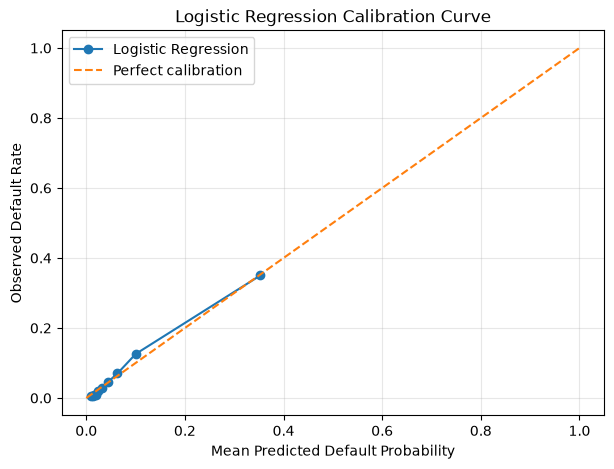

In [8]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Predicted probabilities from our baseline model
probabilities = logreg.predict_proba(X_val)[:, 1]

# Calculate observed default rates in probability bins
fraction_positive, mean_predicted = calibration_curve(
    y_val,
    probabilities,
    n_bins=10,
    strategy="quantile"
)

# Plot calibration curve
plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Rate")
plt.title("Logistic Regression Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. Decision Tree

### 3.1 Prepare Data for Decision Tree

In [9]:
# Load readable training and validation data
train_readable = load_split("train", "readable")
val_readable = load_split("val", "readable")

# Select the same 15 features
X_train_tree = train_readable[SELECTED]
X_val_tree = val_readable[SELECTED]

# Check dimensions
print("Training features:", X_train_tree.shape)
print("Validation features:", X_val_tree.shape)
print("Missing training values:", X_train_tree.isna().sum().sum())
print("Missing validation values:", X_val_tree.isna().sum().sum())

Training features: (96000, 15)
Validation features: (24000, 15)
Missing training values: 0
Missing validation values: 0


### 3.2 Train Baseline Decision Tree

In [10]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the baseline Decision Tree
tree = DecisionTreeClassifier(
    random_state=42
)

# Train the model
tree.fit(X_train_tree, y_train)

# Predict default probabilities on the validation data
y_val_proba_tree = tree.predict_proba(X_val_tree)[:, 1]

# Evaluate performance
auc_tree = roc_auc_score(y_val, y_val_proba_tree)
brier_tree = brier_score_loss(y_val, y_val_proba_tree)

print(f"Validation ROC-AUC: {auc_tree:.4f}")
print(f"Validation Brier Score: {brier_tree:.4f}")
print(f"Tree depth: {tree.get_depth()}")
print(f"Number of leaves: {tree.get_n_leaves()}")

Validation ROC-AUC: 0.6068
Validation Brier Score: 0.1010
Tree depth: 43
Number of leaves: 6642


### 3.3 Hyperparameter Tuning

In [11]:
from sklearn.model_selection import ParameterGrid

tree_results = []

param_grid = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [50, 100, 200]
}

for params in ParameterGrid(param_grid):

    model = DecisionTreeClassifier(
        **params,
        random_state=42
    )

    model.fit(X_train_tree, y_train)

    probabilities = model.predict_proba(X_val_tree)[:, 1]

    tree_results.append({
        **params,
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Brier Score": brier_score_loss(y_val, probabilities)
    })

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df.sort_values(
        "ROC-AUC", ascending=False
    ).round(4)
)

,max_depth,min_samples_leaf,ROC-AUC,Brier Score
11,10,200,0.8517,0.0512
10,10,100,0.8495,0.0510
6,7,50,0.8482,0.0510
8,7,200,0.8481,0.0510
7,7,100,0.8478,0.0508
9,10,50,0.8465,0.0516
5,5,200,0.8441,0.0508
3,5,50,0.8438,0.0508
4,5,100,0.8437,0.0508
2,3,200,0.7949,0.0523


### 3.4 Train the Tuned Decision Tree

In [12]:
# Initialize the tuned Decision Tree
tree_tuned = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=200,
    random_state=42
)

# Train the model
tree_tuned.fit(X_train_tree, y_train)

# Predict default probabilities
y_val_proba_tree_tuned = tree_tuned.predict_proba(X_val_tree)[:, 1]

# Evaluate performance
auc_tree_tuned = roc_auc_score(y_val, y_val_proba_tree_tuned)
brier_tree_tuned = brier_score_loss(y_val, y_val_proba_tree_tuned)

print(f"Validation ROC-AUC: {auc_tree_tuned:.4f}")
print(f"Validation Brier Score: {brier_tree_tuned:.4f}")
print(f"Tree depth: {tree_tuned.get_depth()}")
print(f"Number of leaves: {tree_tuned.get_n_leaves()}")

Validation ROC-AUC: 0.8517
Validation Brier Score: 0.0512
Tree depth: 10
Number of leaves: 113


### 3.5 Evaluate Probability Calibration

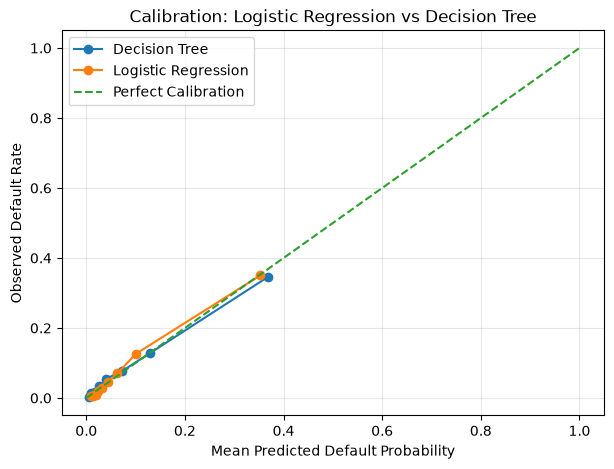

In [13]:
# Calculate calibration curve for the tuned Decision Tree
fraction_positive_tree, mean_predicted_tree = calibration_curve(
    y_val,
    y_val_proba_tree_tuned,
    n_bins=10,
    strategy="quantile"
)

# Plot calibration curves
plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted_tree,
    fraction_positive_tree,
    marker="o",
    label="Decision Tree"
)

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration: Logistic Regression vs Decision Tree")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. XGBoost

### 4.1 Train Baseline XGBoost

In [14]:
from xgboost import XGBClassifier

# Initialize the baseline XGBoost model
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train the model using readable features
xgb.fit(X_train_tree, y_train)

# Predict default probabilities on the validation data
y_val_proba_xgb = xgb.predict_proba(X_val_tree)[:, 1]

# Evaluate performance
auc_xgb = roc_auc_score(y_val, y_val_proba_xgb)
brier_xgb = brier_score_loss(y_val, y_val_proba_xgb)

print(f"Validation ROC-AUC: {auc_xgb:.4f}")
print(f"Validation Brier Score: {brier_xgb:.4f}")

Validation ROC-AUC: 0.8642
Validation Brier Score: 0.0498


### 4.2 Hyperparameter Tuning

In [15]:
xgb_results = []

param_grid = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [100, 200, 300]
}

for params in ParameterGrid(param_grid):

    model = XGBClassifier(
        **params,
        subsample=1.0,
        colsample_bytree=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_tree, y_train)

    probabilities = model.predict_proba(X_val_tree)[:, 1]

    xgb_results.append({
        **params,
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Brier Score": brier_score_loss(y_val, probabilities)
    })

xgb_results_df = pd.DataFrame(xgb_results)

display(
    xgb_results_df.sort_values(
        "ROC-AUC", ascending=False
    ).reset_index(drop=True).round(4)
)

,learning_rate,max_depth,n_estimators,ROC-AUC,Brier Score
0,0.05,4,200,0.8647,0.0497
1,0.10,3,100,0.8647,0.0497
2,0.10,4,100,0.8647,0.0498
3,0.05,3,200,0.8646,0.0497
4,0.05,4,100,0.8646,0.0497
5,0.05,3,300,0.8645,0.0497
6,0.10,3,200,0.8642,0.0498
7,0.05,4,300,0.8641,0.0497
8,0.05,2,300,0.8636,0.0498
9,0.10,2,200,0.8635,0.0499


### 4.3 Train the Tuned XGBoost Model

In [16]:
# Initialize the tuned XGBoost model
xgb_tuned = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_tuned.fit(X_train_tree, y_train)

# Predict default probabilities
y_val_proba_xgb_tuned = xgb_tuned.predict_proba(X_val_tree)[:, 1]

# Evaluate performance
auc_xgb_tuned = roc_auc_score(y_val, y_val_proba_xgb_tuned)
brier_xgb_tuned = brier_score_loss(y_val, y_val_proba_xgb_tuned)

print(f"Validation ROC-AUC: {auc_xgb_tuned:.4f}")
print(f"Validation Brier Score: {brier_xgb_tuned:.4f}")

Validation ROC-AUC: 0.8647
Validation Brier Score: 0.0497


### 4.4 Evaluate Probability Calibration

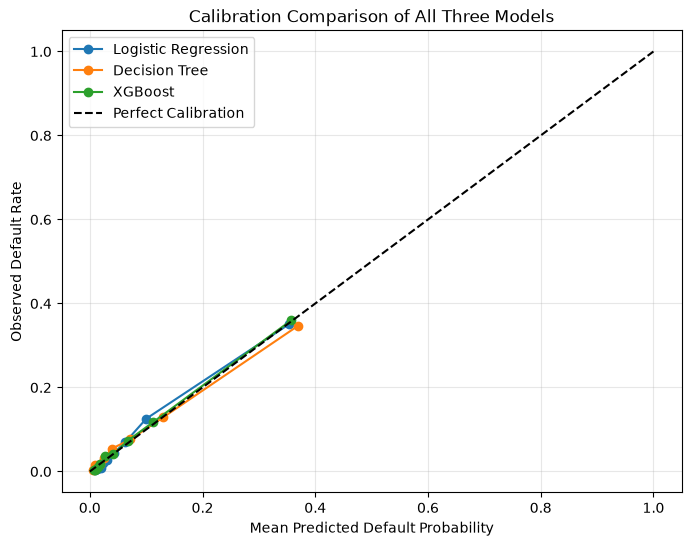

In [17]:
# Calculate XGBoost calibration curve
fraction_positive_xgb, mean_predicted_xgb = calibration_curve(
    y_val,
    y_val_proba_xgb_tuned,
    n_bins=10,
    strategy="quantile"
)

# Plot calibration curves for all three models
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    mean_predicted_tree,
    fraction_positive_tree,
    marker="o",
    label="Decision Tree"
)

plt.plot(
    mean_predicted_xgb,
    fraction_positive_xgb,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration Comparison of All Three Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Model Calibration

### 5.1 Split Validation Data for Calibration

In [18]:
from sklearn.model_selection import train_test_split

# Split validation row indices into two stratified subsets
cal_idx, compare_idx = train_test_split(
    val.index,
    test_size=0.5,
    stratify=y_val,
    random_state=42
)

# Targets for each subset
y_cal = y_val.loc[cal_idx]
y_compare = y_val.loc[compare_idx]

# Logistic Regression uses standardized features
X_cal_logreg = X_val.loc[cal_idx]
X_compare_logreg = X_val.loc[compare_idx]

# Decision Tree and XGBoost use readable features
X_cal_tree = X_val_tree.loc[cal_idx]
X_compare_tree = X_val_tree.loc[compare_idx]

# Check the split
print("Calibration applicants:", len(y_cal))
print("Comparison applicants:", len(y_compare))
print("Calibration default rate:", round(y_cal.mean() * 100, 2), "%")
print("Comparison default rate:", round(y_compare.mean() * 100, 2), "%")
print("Overlapping applicants:", len(set(cal_idx) & set(compare_idx)))

Calibration applicants: 12000
Comparison applicants: 12000
Calibration default rate: 6.68 %
Comparison default rate: 6.68 %
Overlapping applicants: 0


### 5.2 Calibrate Logistic Regression

In [19]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Calibrate the already-trained Logistic Regression model
logreg_calibrated = CalibratedClassifierCV(
    estimator=FrozenEstimator(logreg),
    method="sigmoid"
)

# Fit the calibrator using only the calibration subset
logreg_calibrated.fit(X_cal_logreg, y_cal)

# Predict on the separate comparison subset
proba_original = logreg.predict_proba(X_compare_logreg)[:, 1]
proba_calibrated = logreg_calibrated.predict_proba(X_compare_logreg)[:, 1]

# Compare performance
calibration_results = pd.DataFrame([
    {
        "Model": "Original Logistic Regression",
        "ROC-AUC": roc_auc_score(y_compare, proba_original),
        "Brier Score": brier_score_loss(y_compare, proba_original)
    },
    {
        "Model": "Calibrated Logistic Regression",
        "ROC-AUC": roc_auc_score(y_compare, proba_calibrated),
        "Brier Score": brier_score_loss(y_compare, proba_calibrated)
    }
])

display(calibration_results.round(4))

,Model,ROC-AUC,Brier Score
0,Original Logistic Regression,0.8688,0.0501
1,Calibrated Logistic Regression,0.8688,0.0501


### 5.3 Calibrate Decision Tree

In [20]:
# Calibrate the already-trained Decision Tree
tree_calibrated = CalibratedClassifierCV(
    estimator=FrozenEstimator(tree_tuned),
    method="sigmoid"
)

# Fit the calibrator on the calibration subset
tree_calibrated.fit(X_cal_tree, y_cal)

# Predict on the comparison subset
proba_tree_original = tree_tuned.predict_proba(X_compare_tree)[:, 1]
proba_tree_calibrated = tree_calibrated.predict_proba(X_compare_tree)[:, 1]

# Compare performance
tree_calibration_results = pd.DataFrame([
    {
        "Model": "Original Decision Tree",
        "ROC-AUC": roc_auc_score(y_compare, proba_tree_original),
        "Brier Score": brier_score_loss(y_compare, proba_tree_original)
    },
    {
        "Model": "Calibrated Decision Tree",
        "ROC-AUC": roc_auc_score(y_compare, proba_tree_calibrated),
        "Brier Score": brier_score_loss(y_compare, proba_tree_calibrated)
    }
])

display(tree_calibration_results.round(6))

,Model,ROC-AUC,Brier Score
0,Original Decision Tree,0.856658,0.050784
1,Calibrated Decision Tree,0.856658,0.052194


### 5.4 Calibrate XGBoost

In [21]:
# Calibrate the already-trained XGBoost model
xgb_calibrated = CalibratedClassifierCV(
    estimator=FrozenEstimator(xgb_tuned),
    method="sigmoid"
)

# Fit the calibrator on the calibration subset
xgb_calibrated.fit(X_cal_tree, y_cal)

# Predict on the comparison subset
proba_xgb_original = xgb_tuned.predict_proba(X_compare_tree)[:, 1]
proba_xgb_calibrated = xgb_calibrated.predict_proba(X_compare_tree)[:, 1]

# Compare performance
xgb_calibration_results = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "ROC-AUC": roc_auc_score(y_compare, proba_xgb_original),
        "Brier Score": brier_score_loss(y_compare, proba_xgb_original)
    },
    {
        "Model": "Calibrated XGBoost",
        "ROC-AUC": roc_auc_score(y_compare, proba_xgb_calibrated),
        "Brier Score": brier_score_loss(y_compare, proba_xgb_calibrated)
    }
])

display(xgb_calibration_results.round(6))

,Model,ROC-AUC,Brier Score
0,Original XGBoost,0.871747,0.049068
1,Calibrated XGBoost,0.871747,0.050902


### 5.5 Calibration Summary and Model Selection

All three models were evaluated using sigmoid probability calibration. Calibration did not improve the Brier Score for any of the models, suggesting that their original probability estimates were already reasonably well calibrated.

- Logistic Regression: Calibration had a negligible effect on performance.
- Decision Tree: Calibration increased the Brier Score from 0.050784 to 0.052194.
- XGBoost: Calibration increased the Brier Score from 0.049068 to 0.050902.

Therefore, the original, uncalibrated versions of all three models were selected for the ensemble.

Overall, XGBoost achieved the best individual performance, followed by Logistic Regression and Decision Tree.

These conclusions are based on validation data used during model development. Final performance will be assessed on the untouched test set.

## 6. Ensemble Model

### 6.1 Compare Individual Models

In [22]:
# Compare the three models on the comparison subset
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_compare, proba_original),
        "Brier Score": brier_score_loss(y_compare, proba_original)
    },
    {
        "Model": "Decision Tree",
        "ROC-AUC": roc_auc_score(y_compare, proba_tree_original),
        "Brier Score": brier_score_loss(y_compare, proba_tree_original)
    },
    {
        "Model": "XGBoost",
        "ROC-AUC": roc_auc_score(y_compare, proba_xgb_original),
        "Brier Score": brier_score_loss(y_compare, proba_xgb_original)
    }
])

display(
    model_comparison.sort_values(
        "ROC-AUC", ascending=False
    ).reset_index(drop=True).round(6)
)

,Model,ROC-AUC,Brier Score
0,XGBoost,0.871747,0.049068
1,Logistic Regression,0.868815,0.050057
2,Decision Tree,0.856658,0.050784


### 6.2 Optimize Ensemble Weights

In [23]:
import numpy as np

ensemble_results = []

# Test weights in increments of 0.05
weights = np.linspace(0, 1, 21)

for w_logreg in weights:
    for w_tree in weights:

        w_xgb = 1 - w_logreg - w_tree

        # Skip invalid combinations
        if w_xgb < -1e-10:
            continue

        w_xgb = max(0, w_xgb)

        # Calculate weighted average probabilities
        combined_proba = (
            w_logreg * proba_original
            + w_tree * proba_tree_original
            + w_xgb * proba_xgb_original
        )

        ensemble_results.append({
            "LogReg Weight": w_logreg,
            "Tree Weight": w_tree,
            "XGBoost Weight": w_xgb,
            "ROC-AUC": roc_auc_score(y_compare, combined_proba),
            "Brier Score": brier_score_loss(y_compare, combined_proba)
        })

ensemble_results_df = pd.DataFrame(ensemble_results)

# Display the 10 combinations with the lowest Brier Score
display(
    ensemble_results_df.sort_values(
        "Brier Score", ascending=True
    ).head(10).reset_index(drop=True).round(6)
)

,LogReg Weight,Tree Weight,XGBoost Weight,ROC-AUC,Brier Score
0,0.05,0.05,0.90,0.872139,0.049065
1,0.05,0.00,0.95,0.872002,0.049066
2,0.10,0.05,0.85,0.872350,0.049068
3,0.10,0.00,0.90,0.872205,0.049068
4,0.00,0.00,1.00,0.871747,0.049068
5,0.00,0.05,0.95,0.871904,0.049069
6,0.05,0.10,0.85,0.872203,0.049074
7,0.15,0.05,0.80,0.872493,0.049075
8,0.10,0.10,0.80,0.872376,0.049076
9,0.15,0.00,0.85,0.872349,0.049077


### 6.3 Evaluate the Selected Ensemble

In [24]:
# Selected ensemble weights
ensemble_weights = {
    "logreg": 0.05,
    "tree": 0.05,
    "xgboost": 0.90
}

# Calculate combined default probabilities
proba_ensemble = (
    ensemble_weights["logreg"] * proba_original
    + ensemble_weights["tree"] * proba_tree_original
    + ensemble_weights["xgboost"] * proba_xgb_original
)

# Compare ensemble against the strongest individual model
ensemble_comparison = pd.DataFrame([
    {
        "Model": "XGBoost",
        "ROC-AUC": roc_auc_score(y_compare, proba_xgb_original),
        "Brier Score": brier_score_loss(y_compare, proba_xgb_original)
    },
    {
        "Model": "Weighted Ensemble",
        "ROC-AUC": roc_auc_score(y_compare, proba_ensemble),
        "Brier Score": brier_score_loss(y_compare, proba_ensemble)
    }
])

display(ensemble_comparison.round(6))

# Verify that all predicted probabilities are valid
print("Weights sum to:", sum(ensemble_weights.values()))
print("Minimum ensemble probability:", round(proba_ensemble.min(), 4))
print("Maximum ensemble probability:", round(proba_ensemble.max(), 4))

,Model,ROC-AUC,Brier Score
0,XGBoost,0.871747,0.049068
1,Weighted Ensemble,0.872139,0.049065


Weights sum to: 1.0
Minimum ensemble probability: 0.0049
Maximum ensemble probability: 0.8718


### 6.4 Ensemble Summary

The three models were combined using a weighted average of their predicted default probabilities. Ensemble weights were optimized on the validation comparison subset by minimizing the Brier Score.

The selected weights were 5% Logistic Regression, 5% Decision Tree, and 90% XGBoost.

The ensemble achieved a ROC-AUC of 0.872139 and a Brier Score of 0.049065, compared with 0.871747 and 0.049068 for XGBoost alone.

Although the ensemble slightly improved both metrics, the differences were negligible. XGBoost remained the dominant contributor to the combined prediction.

The selected ensemble will be evaluated on the untouched test set to assess its generalization performance.

## 7. Model Evaluation

### 7.1 Evaluate Different Decision Thresholds

In [25]:
from sklearn.metrics import confusion_matrix

threshold_results = []

# Test different default-risk thresholds
for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:

    # 1 = reject, 0 = approve
    predictions = (proba_ensemble >= threshold).astype(int)

    # Actual vs predicted default
    tn, fp, fn, tp = confusion_matrix(
        y_compare, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Correct Approvals": tn,
        "Wrong Approvals": fn,
        "Wrong Rejections": fp,
        "Correct Rejections": tp,
        "Approval Rate (%)": (tn + fn) / len(y_compare) * 100
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(2))

,Threshold,Correct Approvals,Wrong Approvals,Wrong Rejections,Correct Rejections,Approval Rate (%)
0,0.05,8189,131,3009,671,69.33
1,0.10,9820,252,1378,550,83.93
2,0.15,10419,349,779,453,89.73
3,0.20,10635,413,563,389,92.07
4,0.25,10767,462,431,340,93.58
5,0.30,10885,507,313,295,94.93


### 7.2 Confusion Matrix

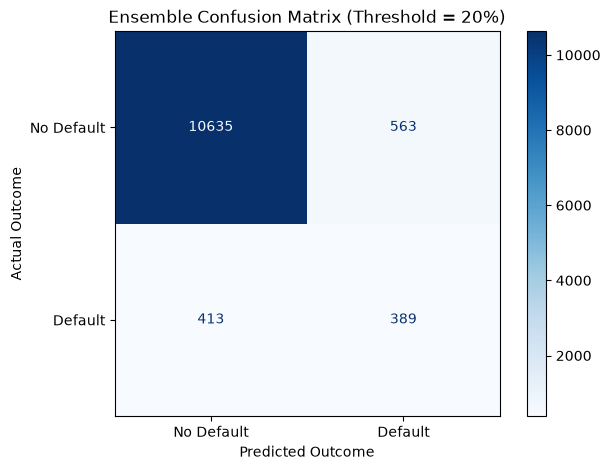

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

# Illustrative decision threshold
threshold = 0.20

# Predict default (1) or no default (0)
y_pred = (proba_ensemble >= threshold).astype(int)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_compare,
    y_pred,
    labels=[0, 1],
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Ensemble Confusion Matrix (Threshold = 20%)")
ax.set_xlabel("Predicted Outcome")
ax.set_ylabel("Actual Outcome")

plt.show()

### 7.3 Classification Performance Metrics

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate the ensemble at the illustrative 20% threshold
threshold = 0.20
y_pred = (proba_ensemble >= threshold).astype(int)

# Calculate classification metrics
tn, fp, fn, tp = confusion_matrix(
    y_compare, y_pred, labels=[0, 1]
).ravel()

classification_metrics = pd.DataFrame([
    {
        "Metric": "Accuracy",
        "Score": accuracy_score(y_compare, y_pred)
    },
    {
        "Metric": "Precision",
        "Score": precision_score(y_compare, y_pred)
    },
    {
        "Metric": "Recall (Sensitivity)",
        "Score": recall_score(y_compare, y_pred)
    },
    {
        "Metric": "Specificity",
        "Score": tn / (tn + fp)
    },
    {
        "Metric": "F1 Score",
        "Score": f1_score(y_compare, y_pred)
    }
])

display(classification_metrics.round(4))

,Metric,Score
0,Accuracy,0.9187
1,Precision,0.4086
2,Recall (Sensitivity),0.4850
3,Specificity,0.9497
4,F1 Score,0.4436


### 7.4 Evaluate Performance for Unusual Applicants

In [28]:
from Source.explain.unusual import load_detector
from Source.data.preprocessing import load_split

# Load Shawn's existing unusual-case detector
detector = load_detector()

# Load the readable and scaled validation datasets
val_readable = load_split("val", "readable")
val_scaled = load_split("val", "model")

# Select the same applicants used in our ensemble evaluation
readable_compare = val_readable.loc[compare_idx]
scaled_compare = val_scaled.loc[compare_idx]

# Check which applicants are unusual
unusual_checks = detector.check(
    readable_compare,
    scaled_compare
)

# Convert the results into a Boolean mask
unusual_mask = np.array([
    check.is_unusual for check in unusual_checks
])

# Display summary
print("Total applicants:", len(unusual_mask))
print("Ordinary applicants:", (~unusual_mask).sum())
print("Unusual applicants:", unusual_mask.sum())
print("Percentage unusual:", round(unusual_mask.mean() * 100, 2), "%")

Total applicants: 12000
Ordinary applicants: 11868
Unusual applicants: 132
Percentage unusual: 1.1 %


### 7.5 Compare Performance for Ordinary and Unusual Applicants

In [29]:
# Compare ensemble performance for ordinary and unusual applicants
unusual_results = []

for group_name, mask in [
    ("Ordinary Applicants", ~unusual_mask),
    ("Unusual Applicants", unusual_mask)
]:
    y_group = np.asarray(y_compare)[mask]
    proba_group = np.asarray(proba_ensemble)[mask]

    unusual_results.append({
        "Group": group_name,
        "Applicants": len(y_group),
        "Default Rate (%)": y_group.mean() * 100,
        "Mean Predicted Default (%)": proba_group.mean() * 100,
        "ROC-AUC": (
            roc_auc_score(y_group, proba_group)
            if len(np.unique(y_group)) == 2 else np.nan
        ),
        "Brier Score": brier_score_loss(y_group, proba_group)
    })

unusual_results_df = pd.DataFrame(unusual_results)

display(unusual_results_df.round(4))

,Group,Applicants,Default Rate (%),Mean Predicted Default (%),ROC-AUC,Brier Score
0,Ordinary Applicants,11868,6.3111,6.1833,0.8686,0.0471
1,Unusual Applicants,132,40.1515,42.9340,0.6568,0.2297


### 7.6 Evaluation Summary

The weighted ensemble was evaluated using different decision thresholds to investigate the trade-off between wrong approvals and wrong rejections.

At an illustrative default-risk threshold of 20%, the model achieved an accuracy of 91.87%, precision of 40.86%, recall of 48.50%, and specificity of 94.97%. These results highlight the importance of considering both types of classification errors when making credit decisions.

Performance was also evaluated separately for ordinary and unusual applicants using the existing unusual-case detector. The ensemble achieved a ROC-AUC of 0.8686 and Brier Score of 0.0471 for ordinary applicants, compared with 0.6568 and 0.2297 for unusual applicants.

The unusual group also had a substantially higher observed default rate (40.15% versus 6.31%). Although the smaller group size and different default rates limit direct comparisons, the results suggest that model predictions are less reliable for unusual applicants.

These findings support including an unusual-case warning and additional human review in the decision support system.

All results in this section are based on validation data. Final model performance will be assessed on the untouched test set.

## 8. Final Test Evaluation

### 8.1 Load the Test Dataset

In [31]:
# Load the untouched test dataset
test = load_split("test", "model")

# Separate features and target
X_test = test[SELECTED]
y_test = test[TARGET]

# Load readable features for Decision Tree and XGBoost
test_readable = load_split("test", "readable")
X_test_tree = test_readable[SELECTED]

# Display dataset information
print("Test dataset:", test.shape)
print("Test features:", X_test.shape)
print("Test target:", y_test.shape)
print("Test default rate:", round(y_test.mean() * 100, 2), "%")

# Check for missing values
print("Missing test values:", X_test.isna().sum().sum())

Test dataset: (30000, 22)
Test features: (30000, 15)
Test target: (30000,)
Test default rate: 6.68 %
Missing test values: 0


### 8.2 Evaluate Individual Models and Ensemble

In [32]:
# Predict default probabilities using the final models
proba_test_logreg = logreg.predict_proba(X_test)[:, 1]
proba_test_tree = tree_tuned.predict_proba(X_test_tree)[:, 1]
proba_test_xgb = xgb_tuned.predict_proba(X_test_tree)[:, 1]

# Combine predictions using the selected ensemble weights
proba_test_ensemble = (
    ensemble_weights["logreg"] * proba_test_logreg
    + ensemble_weights["tree"] * proba_test_tree
    + ensemble_weights["xgboost"] * proba_test_xgb
)

# Evaluate each model
test_results = []

models = {
    "Logistic Regression": proba_test_logreg,
    "Decision Tree": proba_test_tree,
    "XGBoost": proba_test_xgb,
    "Weighted Ensemble": proba_test_ensemble
}

for name, probabilities in models.items():
    test_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Brier Score": brier_score_loss(y_test, probabilities)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        "ROC-AUC", ascending=False
    ).reset_index(drop=True).round(6)
)

,Model,ROC-AUC,Brier Score
0,Weighted Ensemble,0.868301,0.048738
1,XGBoost,0.868241,0.048747
2,Logistic Regression,0.863962,0.049767
3,Decision Tree,0.852109,0.050479


### 8.3 Evaluate Approval Decisions on Test Data

In [33]:
# Use the same illustrative threshold as in Section 7
test_threshold = 0.20

# Convert default probabilities into decisions
# 0 = approve, 1 = reject
y_test_pred = (proba_test_ensemble >= test_threshold).astype(int)

# Calculate the confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

# Summarize approval decisions
test_decision_results = pd.DataFrame([
    {
        "Threshold": test_threshold,
        "Correct Approvals": tn,
        "Wrong Approvals": fn,
        "Wrong Rejections": fp,
        "Correct Rejections": tp,
        "Approval Rate (%)": (tn + fn) / len(y_test) * 100,
        "Recall (%)": recall_score(y_test, y_test_pred) * 100,
        "Specificity (%)": tn / (tn + fp) * 100
    }
])

display(test_decision_results.round(2))

,Threshold,Correct Approvals,Wrong Approvals,Wrong Rejections,Correct Rejections,Approval Rate (%),Recall (%),Specificity (%)
0,0.2,26559,1019,1436,986,91.93,49.18,94.87


### 8.4 Evaluate Performance for Unusual Applicants

In [34]:
# Load both representations of the test dataset
test_readable = load_split("test", "readable")
test_scaled = load_split("test", "model")

# Use Shawn's existing unusual-case detector
test_unusual_checks = detector.check(
    test_readable,
    test_scaled
)

# Identify unusual applicants
test_unusual_mask = np.array([
    check.is_unusual for check in test_unusual_checks
])

# Compare ensemble performance for both groups
test_unusual_results = []

for group_name, mask in [
    ("Ordinary Applicants", ~test_unusual_mask),
    ("Unusual Applicants", test_unusual_mask)
]:
    y_group = np.asarray(y_test)[mask]
    proba_group = np.asarray(proba_test_ensemble)[mask]

    test_unusual_results.append({
        "Group": group_name,
        "Applicants": len(y_group),
        "Default Rate (%)": y_group.mean() * 100,
        "Mean Predicted Default (%)": proba_group.mean() * 100,
        "ROC-AUC": (
            roc_auc_score(y_group, proba_group)
            if len(np.unique(y_group)) == 2 else np.nan
        ),
        "Brier Score": brier_score_loss(y_group, proba_group)
    })

test_unusual_results_df = pd.DataFrame(test_unusual_results)

display(test_unusual_results_df.round(4))

,Group,Applicants,Default Rate (%),Mean Predicted Default (%),ROC-AUC,Brier Score
0,Ordinary Applicants,29663,6.2030,6.2069,0.8616,0.0468
1,Unusual Applicants,337,48.9614,46.9091,0.7128,0.2181


### 8.5 Final Test Evaluation Summary

The three trained models and their weighted ensemble were evaluated on the untouched test set containing 30,000 applicants.

The weighted ensemble achieved the best overall performance, with a ROC-AUC of 0.8683 and a Brier Score of 0.0487. However, its improvement over XGBoost alone was negligible.

At an illustrative default-risk threshold of 20%, the ensemble achieved a recall of 49.18% and specificity of 94.87%. This demonstrates the trade-off between identifying applicants likely to default and avoiding unnecessary rejections.

Performance was also evaluated separately for ordinary and unusual applicants. The ensemble achieved a ROC-AUC of 0.8616 and Brier Score of 0.0468 for ordinary applicants, compared with 0.7128 and 0.2181 for unusual applicants.

The unusual group had a substantially higher observed default rate (48.96% versus 6.20%). Although differences in default prevalence and group size affect the comparison, the results indicate that unusual applicants present a greater prediction challenge.

Overall, the ensemble demonstrated similar performance on validation and test data, suggesting reasonable generalization. The findings also support including an unusual-case warning and additional human review in the decision support system.

## 9. Save Final Models

### 9.1 Save Trained Models and Ensemble Weights

In [36]:
from pathlib import Path
import joblib
import json

# Create the Models directory if it does not exist
models_dir = Path("../Models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the three trained models
joblib.dump(logreg, models_dir / "logistic_regression.joblib")
joblib.dump(tree_tuned, models_dir / "decision_tree.joblib")
joblib.dump(xgb_tuned, models_dir / "xgboost.joblib")

# Save the ensemble configuration
ensemble_config = {
    "weights": ensemble_weights,
    "features": SELECTED,
    "feature_representation": {
        "logreg": "model",
        "tree": "readable",
        "xgboost": "readable"
    },
    "decision_threshold": 0.20
}

with open(models_dir / "ensemble_config.json", "w") as f:
    json.dump(ensemble_config, f, indent=4)

print("Models and ensemble configuration saved successfully.")

Models and ensemble configuration saved successfully.


### 9.2 Verify Saved Models

In [37]:
# Load the saved models
loaded_logreg = joblib.load(models_dir / "logistic_regression.joblib")
loaded_tree = joblib.load(models_dir / "decision_tree.joblib")
loaded_xgb = joblib.load(models_dir / "xgboost.joblib")

# Load the saved ensemble configuration
with open(models_dir / "ensemble_config.json", "r") as f:
    loaded_config = json.load(f)

# Predict using the loaded models
loaded_proba_logreg = loaded_logreg.predict_proba(X_test)[:, 1]
loaded_proba_tree = loaded_tree.predict_proba(X_test_tree)[:, 1]
loaded_proba_xgb = loaded_xgb.predict_proba(X_test_tree)[:, 1]

# Combine predictions using the saved weights
weights = loaded_config["weights"]

loaded_proba_ensemble = (
    weights["logreg"] * loaded_proba_logreg
    + weights["tree"] * loaded_proba_tree
    + weights["xgboost"] * loaded_proba_xgb
)

# Verify that saved models reproduce the original predictions
print("Logistic Regression matches:",
      np.allclose(loaded_proba_logreg, proba_test_logreg))

print("Decision Tree matches:",
      np.allclose(loaded_proba_tree, proba_test_tree))

print("XGBoost matches:",
      np.allclose(loaded_proba_xgb, proba_test_xgb))

print("Ensemble matches:",
      np.allclose(loaded_proba_ensemble, proba_test_ensemble))

print("\nSaved ensemble weights:", weights)

Logistic Regression matches: True
Decision Tree matches: True
XGBoost matches: True
Ensemble matches: True

Saved ensemble weights: {'logreg': 0.05, 'tree': 0.05, 'xgboost': 0.9}
